# Correção de exposição por histograma

**Disciplina:** Processamento de Imagens  \
**Aluno:** `Felipe Cruz`  \
**Turma:** CC8NA  \

Foram tiradas três fotos do mesmo sapato com iluminações diferentes:

- `sapato_1.jpeg` — **escura demais** (ambiente interno mal iluminado);
- `sapato_2.jpeg` — **bem exposta**;
- `sapato_3.jpeg` — **clara demais** (excesso de luz, aparência lavada).

Para cada uma: conversão para tons de cinza, histograma, diagnóstico, aplicação de **uma única** operação (expansão de contraste, equalização ou correção gamma) e comparação antes/depois.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

caminhos = {
    1: 'sapato_1.jpeg',
    2: 'sapato_2.jpeg',
    3: 'sapato_3.jpeg',
}

imagens = {}
for numero, caminho in caminhos.items():
    img = cv2.imread(caminho)
    if img is None:
        raise FileNotFoundError(f'Não foi possível abrir: {caminho}')
    imagens[numero] = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print('Três imagens carregadas e convertidas para tons de cinza.')

Três imagens carregadas e convertidas para tons de cinza.


In [2]:
def calclist(img):
    bars = np.zeros(shape=256, dtype=np.int64)

    for pixel in img.ravel():
        bars[pixel] += 1

    return bars


def plotar_histograma(ax, img, titulo):
    hist = calclist(img)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Intensidade (0 a 255)')
    ax.set_ylabel('Quantidade de pixels')
    ax.bar(range(256), hist, color='purple', width=0.8, edgecolor='none')
    ax.set_xlim([0, 255])
    ax.grid(axis='y', alpha=0.25)
    return hist


def mostrar_imagem_e_histograma(img, titulo):
    # Imagem em tons de cinza ao lado do seu histograma.
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title(titulo, fontweight='bold')
    ax[0].axis('off')

    plotar_histograma(ax[1], img, 'Histograma')
    plt.tight_layout()
    plt.show()


def mostrar_comparacao(original, resultado, titulo_original, titulo_resultado):
    # O arranjo 2x2 reúne imagens e seus histogramas antes/depois.
    fig, ax = plt.subplots(2, 2, figsize=(15, 12))
    ax[0, 0].imshow(original, cmap='gray', vmin=0, vmax=255)
    ax[0, 0].set_title(titulo_original, fontweight='bold')
    ax[0, 0].axis('off')

    ax[0, 1].imshow(resultado, cmap='gray', vmin=0, vmax=255)
    ax[0, 1].set_title(titulo_resultado, fontweight='bold')
    ax[0, 1].axis('off')

    plotar_histograma(ax[1, 0], original, 'Histograma antes')
    plotar_histograma(ax[1, 1], resultado, 'Histograma depois')
    plt.tight_layout()
    plt.show()


def resumo_numerico(img):
    # Estatísticas simples que ajudam a sustentar o diagnóstico.
    print(f'mínimo = {img.min()} | máximo = {img.max()} | média = {img.mean():.2f} | desvio padrão = {img.std():.2f}')

    # Percentual de pixels em cada terço da escala de cinza.
    sombras = np.mean(img < 85) * 100
    medios = np.mean((img >= 85) & (img < 170)) * 100
    altas_luzes = np.mean(img >= 170) * 100
    print(f'sombras (0-84) = {sombras:.1f}% | tons médios (85-169) = {medios:.1f}% | altas luzes (170-255) = {altas_luzes:.1f}%')

# Funções de correção de imagem

In [3]:
# Correção Gamma

def correcao_gama(img: np.ndarray, nivel_gamma: np.float32) -> np.ndarray:
  normalizada = img.astype(np.float32) / 255.0 # normaliza entre 0 e 1
  img_gamma = 255.0 * (normalizada ** nivel_gamma) # aplica o nível de gamma em potencia
  img_gamma = np.clip(img_gamma, 0, 255).astype(np.uint8) # volta para 0 a 255
  return img_gamma



# Equalização

def equalizar_manual(img):
    hist = calclist(img)
    cdf = np.cumsum(hist)

    # Primeiro valor não nulo da CDF: evita mapear níveis ausentes de forma indevida.
    cdf_min = cdf[cdf > 0][0]
    total = img.size

    # LUT explícita: cada índice r recebe a intensidade transformada s.
    lut = (cdf - cdf_min) * 255.0 / (total - cdf_min)
    lut = np.clip(np.round(lut), 0, 255).astype(np.uint8)
    return lut[img]



# Expansão

def expandir_contraste(img, L=None, H=None):
    # Sem L e H informados, usa o menor e o maior nível da própria imagem.
    if L is None:
        L = int(img.min())
    if H is None:
        H = int(img.max())

    if H == L:
        return img.copy()

    # Cálculo em float evita truncamento durante a transformação linear.
    expandida = (img.astype(np.float32) - L) * 255.0 / (H - L)
    return np.clip(expandida, 0, 255).astype(np.uint8)

# Caso 1 — Imagem escura (`sapato_1.jpeg`)

mínimo = 0 | máximo = 116 | média = 44.69 | desvio padrão = 17.07
sombras (0-84) = 99.8% | tons médios (85-169) = 0.2% | altas luzes (170-255) = 0.0%


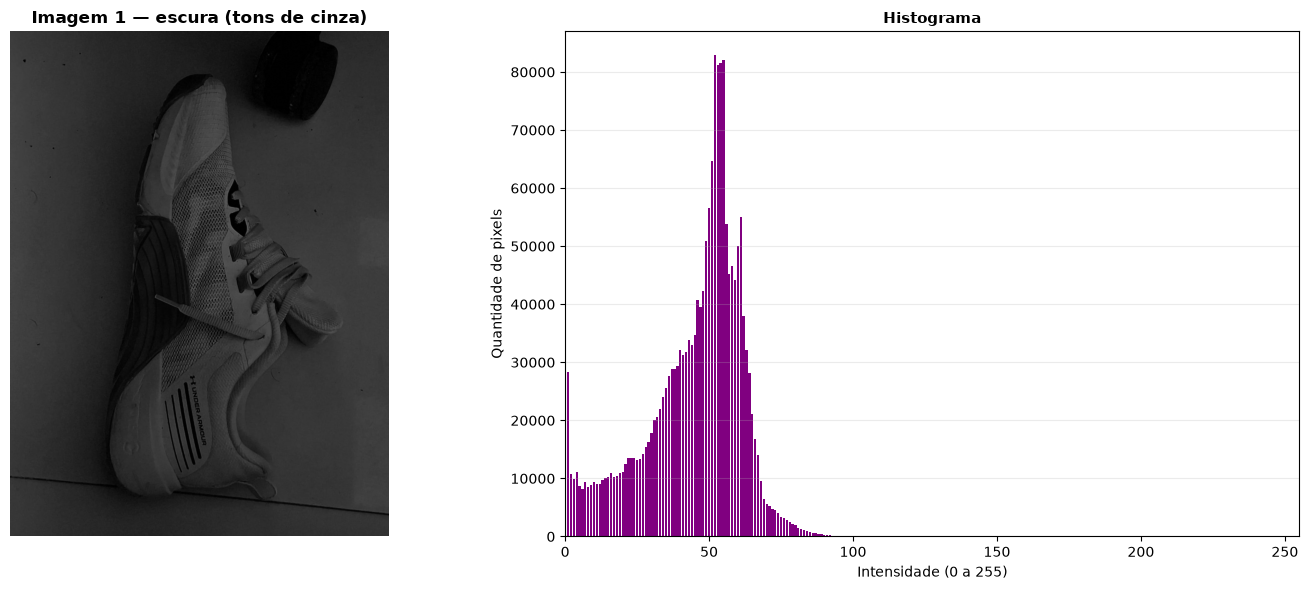

In [4]:
img1 = imagens[1]

resumo_numerico(img1)
mostrar_imagem_e_histograma(img1, 'Imagem 1 — escura (tons de cinza)')

**Diagnóstico.** As intensidades estão concentradas no início da escala: quase todos os pixels ficam entre 0 e 80, a média é de aproximadamente 45 e nenhum pixel passa de 116. A metade superior do histograma está vazia, o que indica uma foto subexposta, com os detalhes do sapato (malha, cadarço e logotipo) escondidos nas sombras.

**Operação e parâmetro.** Correção gamma com `γ = 0.4`. Como `γ < 1`, a curva `s = 255 (r/255)^γ` se eleva principalmente nos tons baixos, clareando as sombras sem saturar os poucos pontos mais claros. A equalização também clarearia, mas tende a exagerar o ruído típico de fotos com pouca luz.

mínimo = 0 | máximo = 186 | média = 122.73 | desvio padrão = 26.33
sombras (0-84) = 9.3% | tons médios (85-169) = 90.7% | altas luzes (170-255) = 0.0%


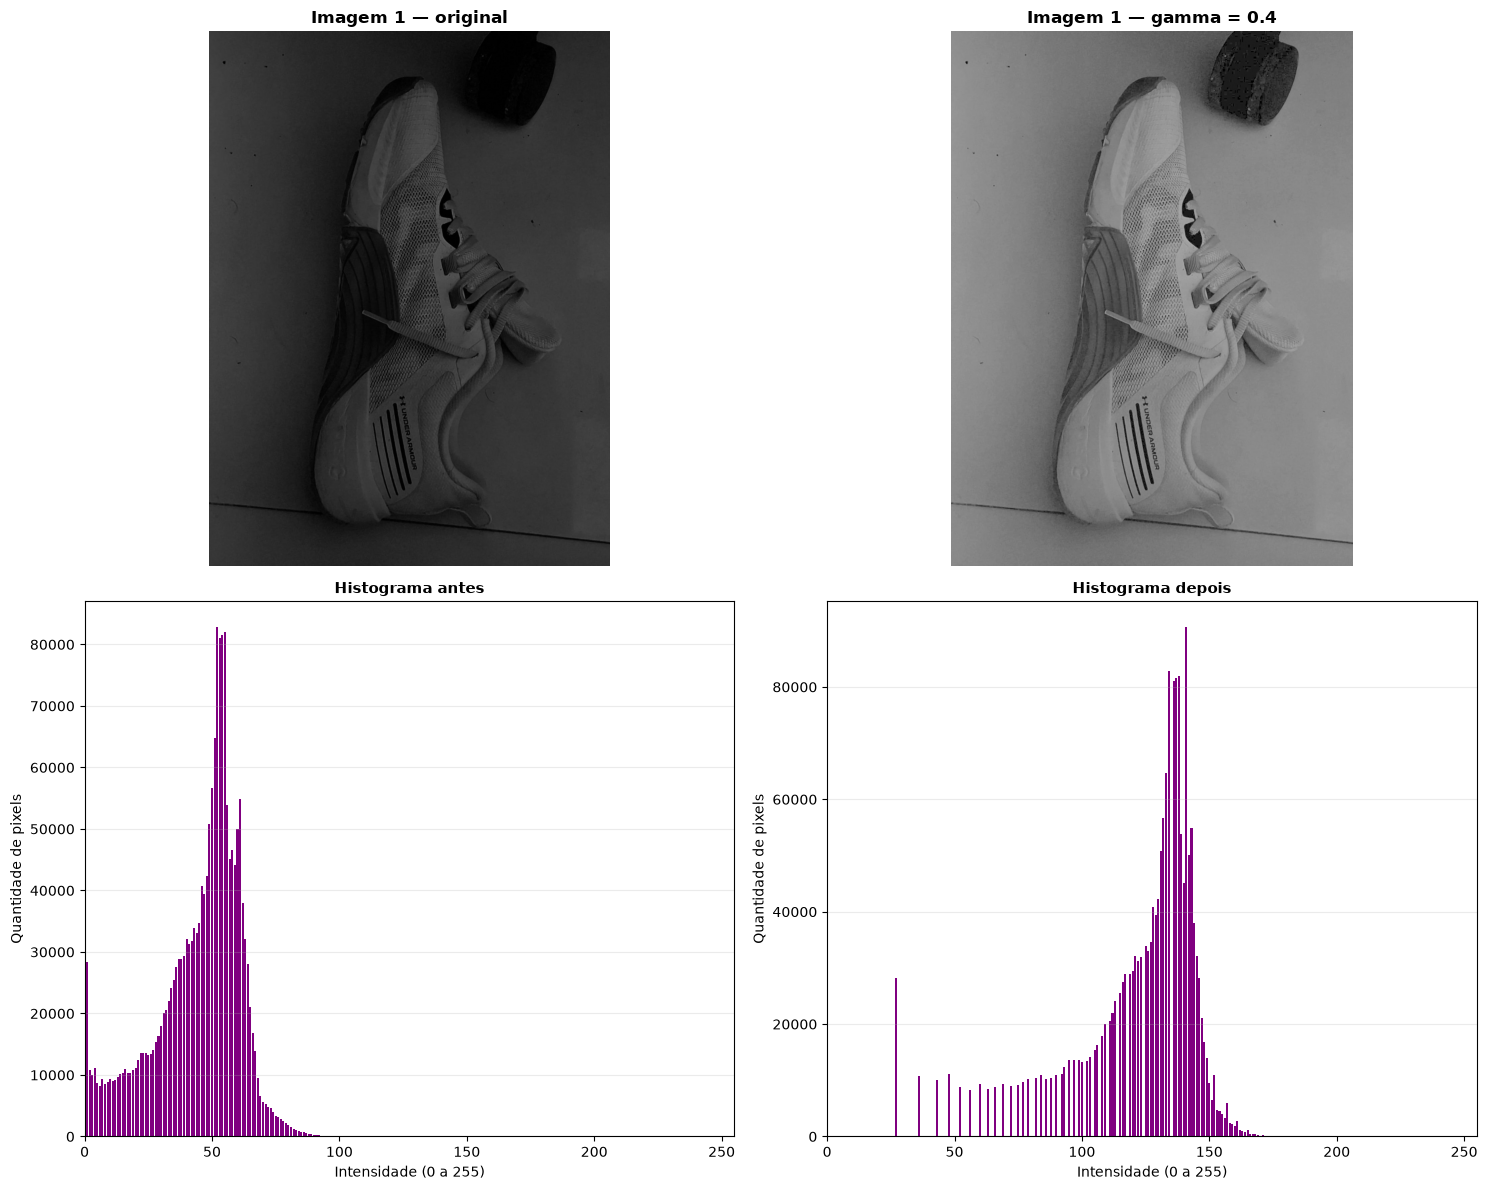

In [5]:
gamma1 = correcao_gama(img=img1, nivel_gamma=0.4)

resumo_numerico(gamma1)
mostrar_comparacao(img1, gamma1, 'Imagem 1 — original', f'Imagem 1 — gamma = {0.4}')

**Justificativa.** O histograma foi deslocado para a direita e passou a ocupar os tons médios, com a média subindo de cerca de 45 para cerca de 123. A malha, os cadarços, as listras do logotipo e o objeto escuro no canto ficaram visíveis. Os níveis mais baixos aparecem espaçados no novo histograma, porque poucos tons originais foram esticados para uma faixa maior. Como o pico principal continua estreito, a imagem fica clara, mas um pouco acinzentada: a gamma corrige o brilho, não o contraste.

# Caso 2 — Imagem bem exposta (`sapato_2.jpeg`)

mínimo = 0 | máximo = 229 | média = 137.61 | desvio padrão = 26.64
sombras (0-84) = 5.9% | tons médios (85-169) = 92.7% | altas luzes (170-255) = 1.4%


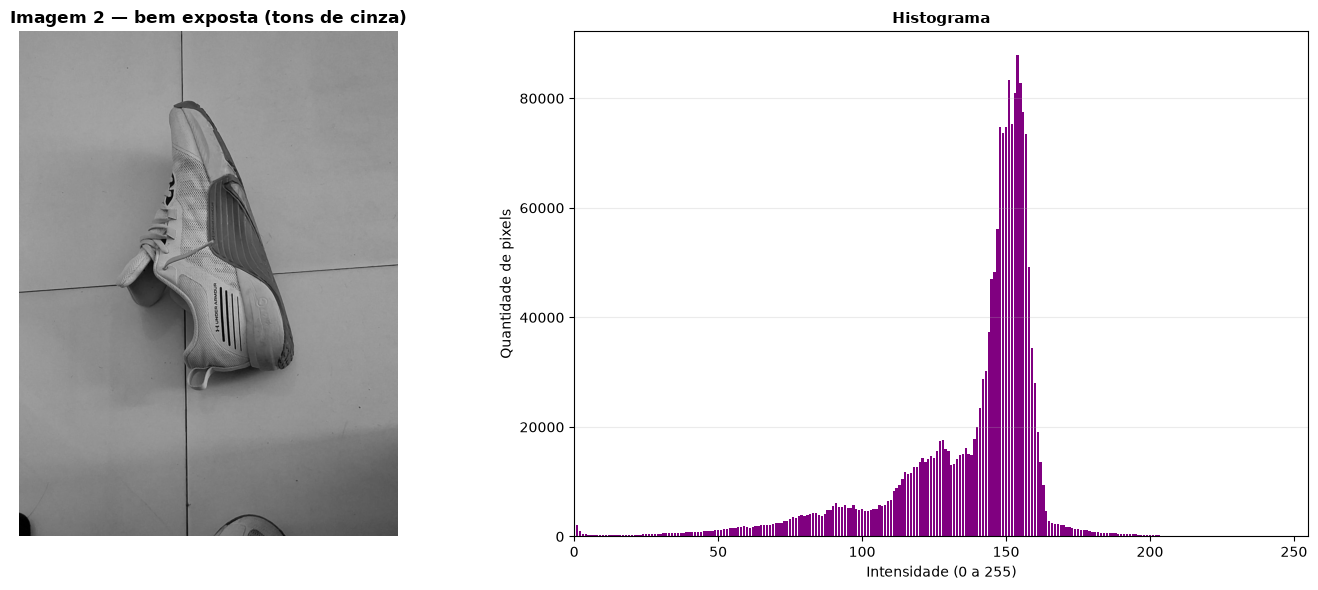

In [6]:
img2 = imagens[2]

resumo_numerico(img2)
mostrar_imagem_e_histograma(img2, 'Imagem 2 — bem exposta (tons de cinza)')

**Diagnóstico.** O histograma tem um pico nos tons médios-claros (por volta de 145 a 160), que corresponde ao piso, e se espalha de 0 (listras pretas do logotipo) até 229. Não há acúmulo nos extremos nem pixels estourados em 255, o que indica uma foto corretamente exposta, com sombras e altas luzes preservadas.

**Operação e parâmetro.** Expansão de contraste com `L = 0` e `H = 229` (menor e maior nível da própria imagem). Como a exposição já está adequada, a ideia é apenas aproveitar o restante da escala sem alterar a distribuição dos tons. Gamma mudaria a exposição que já está boa, e a equalização redistribuiria o pico do piso, realçando textura e ruído sem necessidade.

mínimo = 0 | máximo = 255 | média = 152.74 | desvio padrão = 29.66
sombras (0-84) = 4.3% | tons médios (85-169) = 64.5% | altas luzes (170-255) = 31.2%


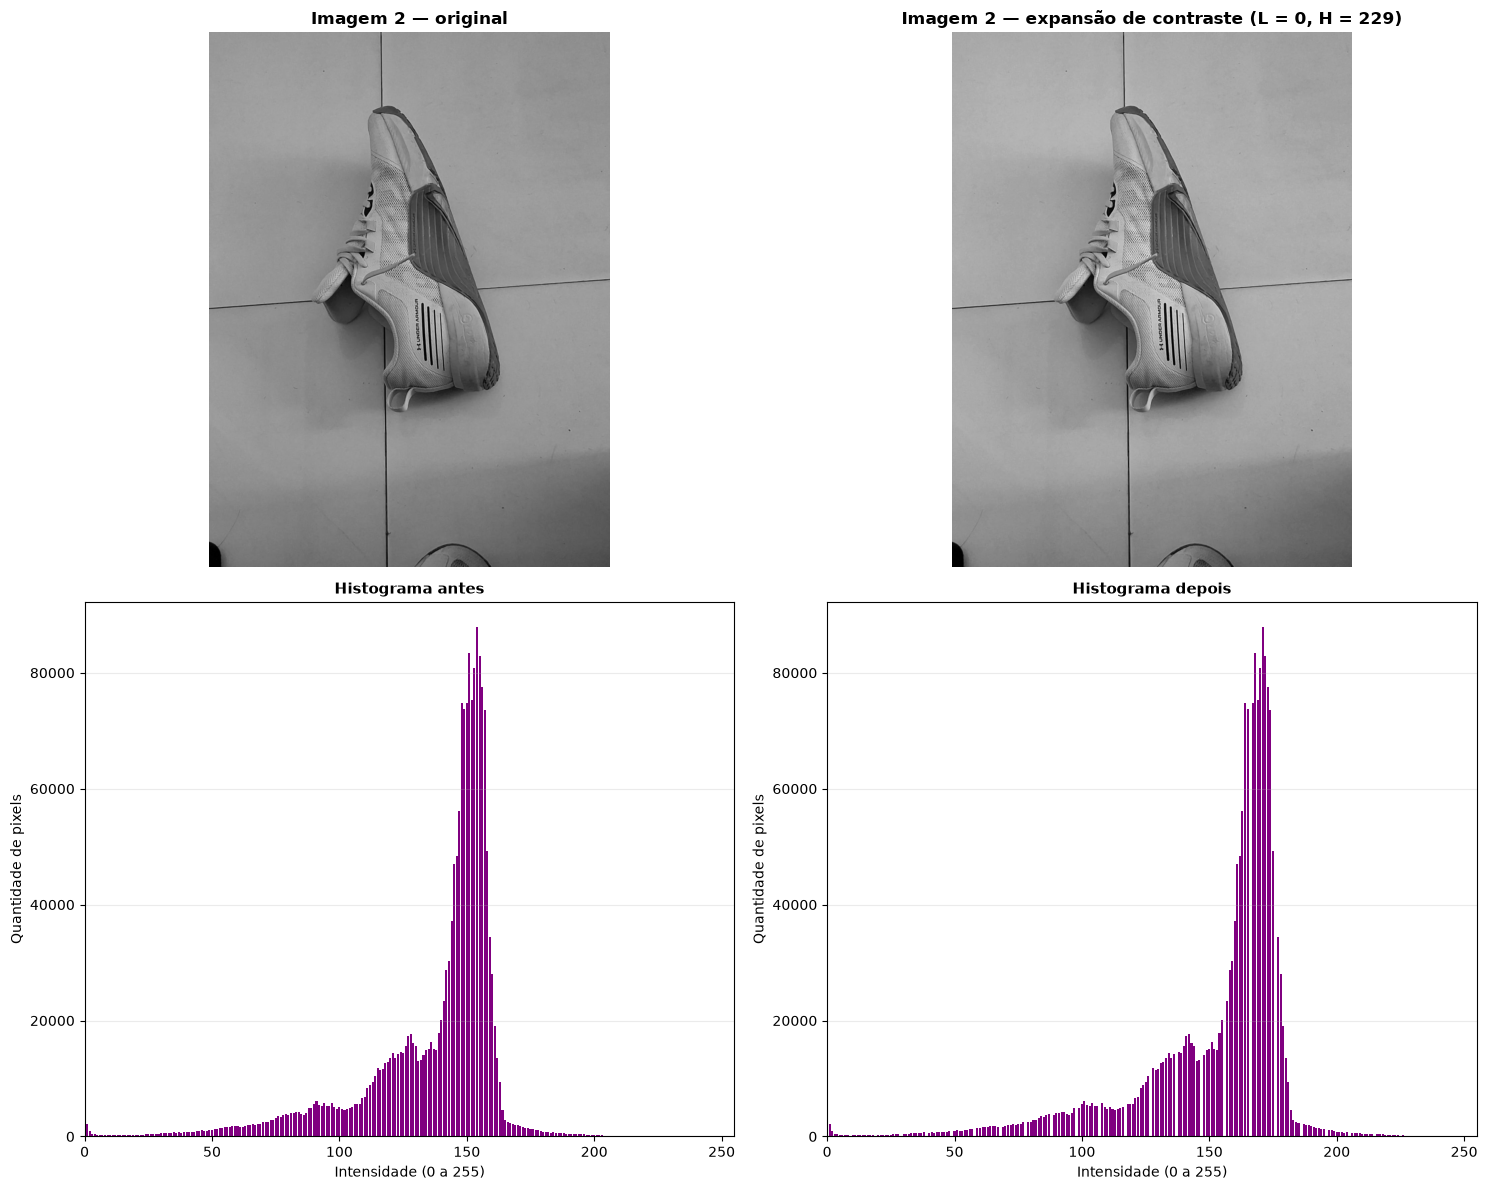

In [7]:
expandida2 = expandir_contraste(img2, L=0, H=229)

resumo_numerico(expandida2)
mostrar_comparacao(img2, expandida2, 'Imagem 2 — original', 'Imagem 2 — expansão de contraste (L = 0, H = 229)')

**Justificativa.** A transformação é linear e multiplica cada nível por apenas `255 / 229 ≈ 1.11`. O histograma final tem praticamente o mesmo formato, só um pouco esticado até 255, e a imagem fica um pouco mais clara. Isso confirma que a foto já usava quase toda a faixa dinâmica.

# Caso 3 — Imagem clara demais (`sapato_3.jpeg`)

mínimo = 0 | máximo = 255 | média = 201.85 | desvio padrão = 32.15
sombras (0-84) = 1.7% | tons médios (85-169) = 9.7% | altas luzes (170-255) = 88.6%


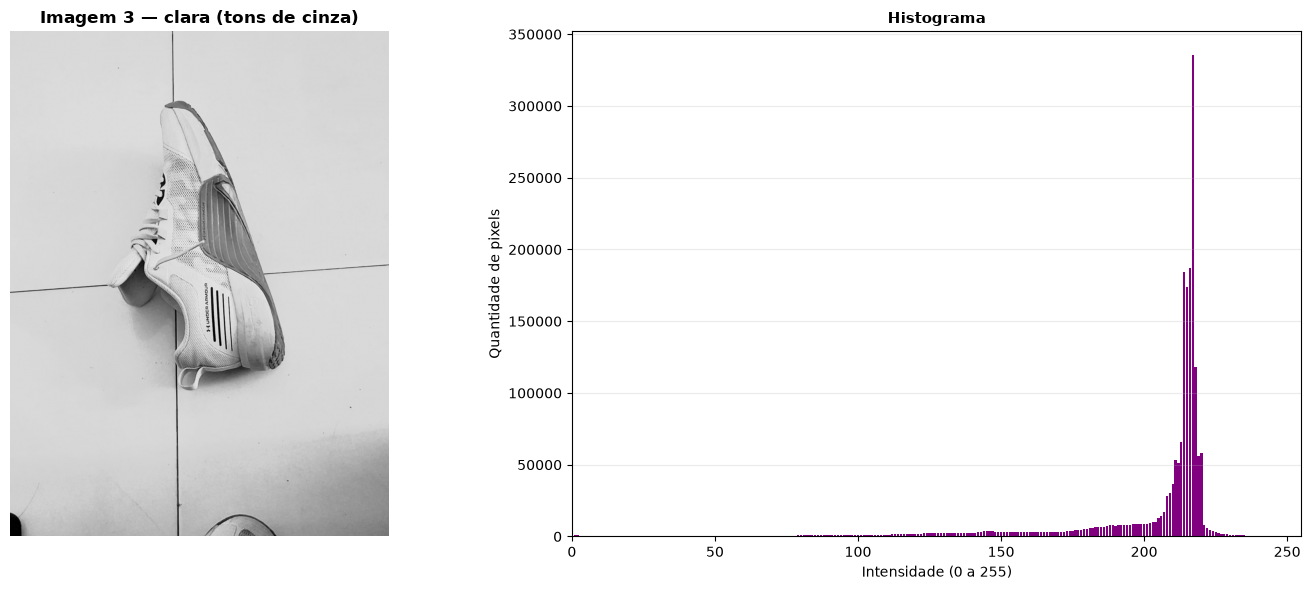

In [8]:
img3 = imagens[3]

resumo_numerico(img3)
mostrar_imagem_e_histograma(img3, 'Imagem 3 — clara (tons de cinza)')

**Diagnóstico.** As intensidades estão concentradas no final da escala: a maior parte dos pixels fica em uma faixa estreita entre aproximadamente 200 e 225, com média de cerca de 202. O piso e o sapato branco ficam quase com o mesmo tom, o que indica uma foto superexposta e lavada, com pouca separação entre os tons claros.

**Operação e parâmetro.** Correção gamma com `γ = 2.0`. Como `γ > 1`, a curva escurece a imagem e, na região clara, a inclinação fica maior que 1, ou seja, a pequena diferença entre os tons altos é ampliada. A expansão de contraste não teria efeito pelos limites mínimo/máximo, porque a imagem já vai de 0 a 255 (há pixels pretos no logotipo e no canto).

mínimo = 0 | máximo = 255 | média = 163.28 | desvio padrão = 39.45
sombras (0-84) = 7.7% | tons médios (85-169) = 19.7% | altas luzes (170-255) = 72.6%


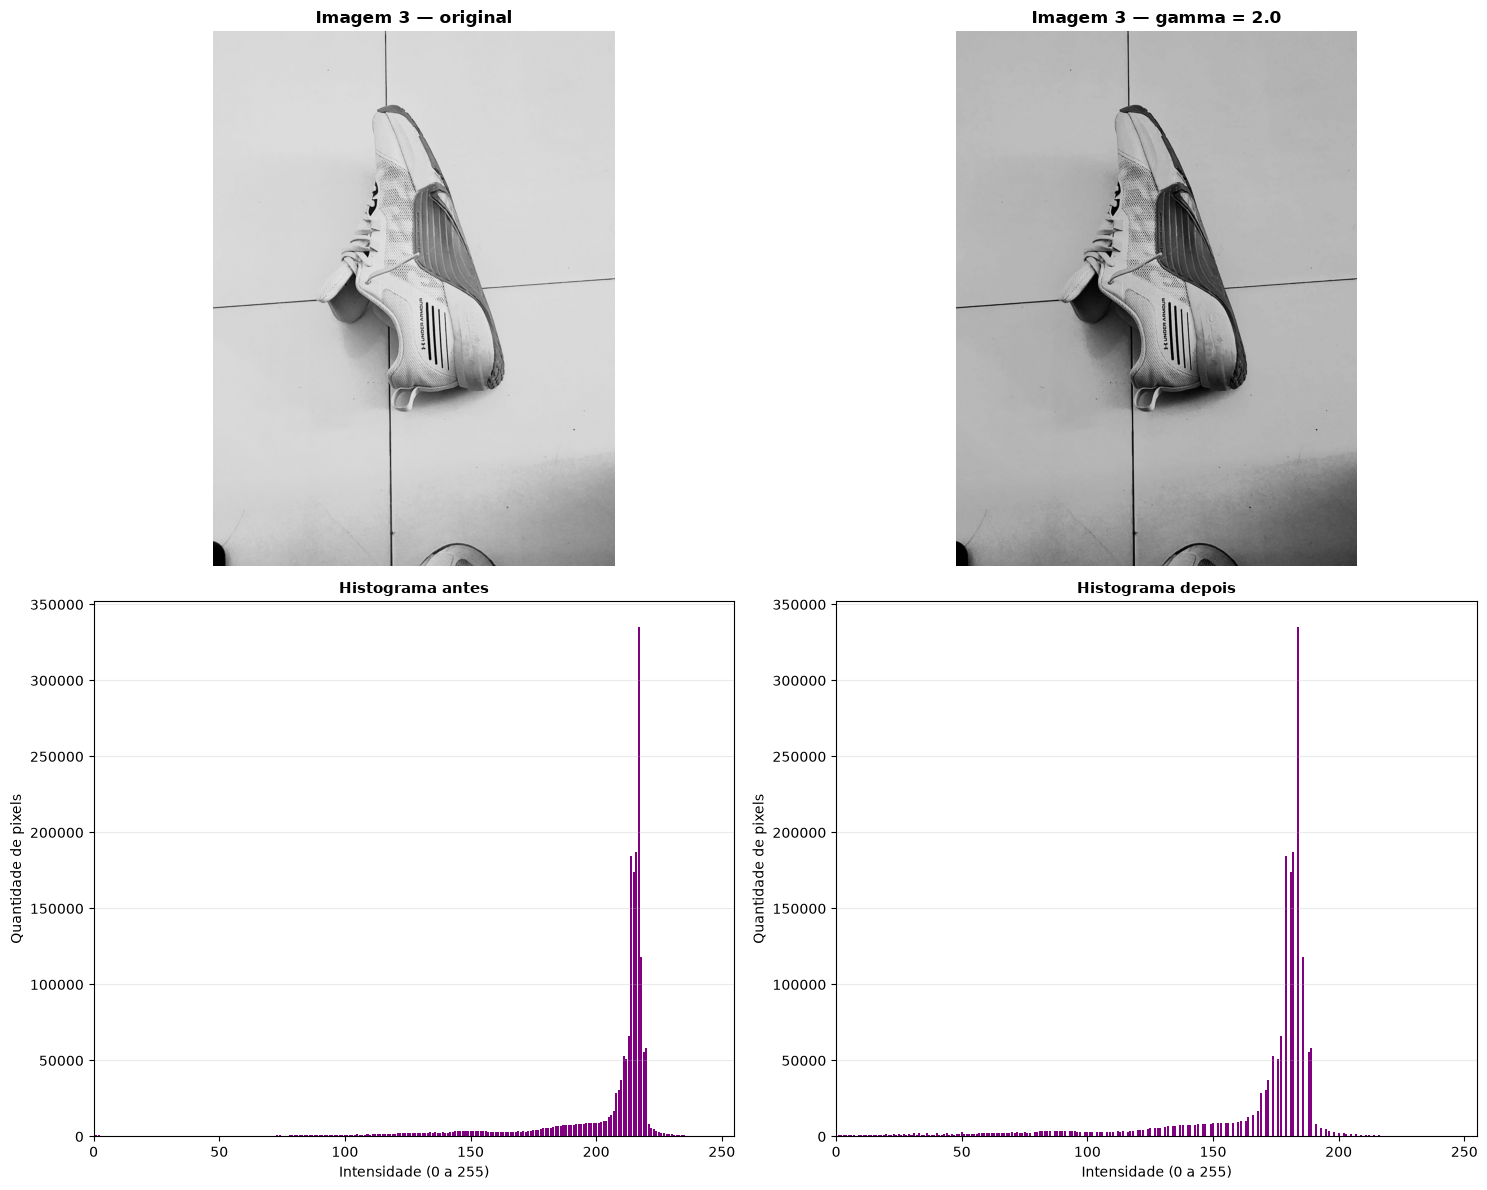

In [9]:
gamma3 = correcao_gama(img=img3, nivel_gamma=2.0)

resumo_numerico(gamma3)
mostrar_comparacao(img3, gamma3, 'Imagem 3 — original', f'Imagem 3 — gamma = {2.0}')

**Justificativa.** A massa do histograma foi deslocada para a esquerda (média de cerca de 202 para cerca de 163) e ficou um pouco mais espalhada (desvio padrão de cerca de 32 para cerca de 39). Isso separa melhor o piso, a parte branca do sapato e a sola, e deixa a imagem com um brilho mais próximo do da foto bem exposta. Detalhes que a luz excessiva já apagou na captura não podem ser recuperados, pois a informação não existe na imagem.

# Comparação final

In [10]:
resultados = {
    'Imagem 1 (escura) — gamma 0.4': (img1, gamma1),
    'Imagem 2 (bem exposta) — expansão L = 0, H = 229': (img2, expandida2),
    'Imagem 3 (clara) — gamma 2.0': (img3, gamma3),
}

# Diferença média absoluta entre os pixels antes e depois da operação.
for nome, (antes, depois) in resultados.items():
    diferenca = np.abs(antes.astype(np.int16) - depois.astype(np.int16)).mean()
    print(f'{nome}: diferença média = {diferenca:.2f} níveis de cinza')

Imagem 1 (escura) — gamma 0.4: diferença média = 78.04 níveis de cinza
Imagem 2 (bem exposta) — expansão L = 0, H = 229: diferença média = 15.13 níveis de cinza
Imagem 3 (clara) — gamma 2.0: diferença média = 38.57 níveis de cinza


**Em qual das três imagens a operação fez menos diferença? Por quê?**

A operação fez menos diferença na **imagem 2 (bem exposta)**. Seu histograma já estava distribuído por quase toda a escala (de 0 a 229), sem acúmulo nas sombras nem nas altas luzes, então a expansão de contraste só esticou levemente a faixa até 255, com um fator de aproximadamente 1.11, e os pixels mudaram em média cerca de 15 níveis. Nas imagens escura e clara, o histograma estava comprimido em uma ponta da escala, então a correção gamma precisou deslocar os tons de forma muito mais intensa, mudando os pixels em média cerca de 78 níveis (imagem escura) e 39 níveis (imagem clara). Ou seja, quanto mais próxima da exposição correta a imagem está, menos espaço sobra para uma transformação de intensidade melhorá-la.